In [ ]:
## WORK IN PROGRESS

In [67]:
%pip install seaborn matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------------- -------------------- 4.7/9.5 MB 23.5 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 23.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 22.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 16.3 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [kiwisolver]
   ----------- ---------------------------- 2/7 [fonttools]
   ----------- ---------------------------- 2/7 [fonttools]
   ----------- ---------------------------- 2/7 [fonttools]
   ----------- ---------------------------- 2/7 [fonttools]
   ----------- ---------------------------- 2/7 [fonttools]
   ----------- ---------------------------- 2/7 [fonttools]
   ----------- ---------------------------- 2/7 [fonttools]
   ----------- ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\tngya\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [83]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

In [72]:
df = pd.read_csv("../dataset/hotel_booking_cleaned.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 41 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   booking_id                      119390 non-null  int64  
 1   hotel                           119390 non-null  str    
 2   is_canceled                     119390 non-null  int64  
 3   lead_time                       119390 non-null  int64  
 4   arrival_date_year               119390 non-null  int64  
 5   arrival_date_month              119390 non-null  str    
 6   arrival_date_week_number        119390 non-null  int64  
 7   arrival_date_day_of_month       119390 non-null  int64  
 8   stays_in_weekend_nights         119390 non-null  int64  
 9   stays_in_week_nights            119390 non-null  int64  
 10  adults                          119390 non-null  int64  
 11  children                        119390 non-null  float64
 12  babies                     

In [69]:
## Overall booking summary

In [63]:
# Total number of bookings
total_bookings = len(df)
total_bookings_by_hotel = df.groupby('hotel').size()

canceled_by_hotel = df[df['reservation_status'] == 'Canceled'].groupby('hotel').size()
cancellation_rate = canceled_by_hotel / total_bookings_by_hotel 

rev_by_hotel = df.groupby('hotel')['estimated_room_revenue'].sum()
nights_by_hotel = df.groupby('hotel')['total_nights'].sum()
weighted_adr_by_hotel = rev_by_hotel / nights_by_hotel
overall_adr = df['estimated_room_revenue'].sum() / df['total_nights'].sum()


hotel_summary = pd.DataFrame({
    'Total Bookings': total_bookings_by_hotel,
    'Canceled Bookings': canceled_by_hotel,
    'Canceled Rate': cancellation_rate,
    'Weighted ADR': weighted_adr_by_hotel
})

total_canceled = (df['reservation_status'] == 'Canceled').sum()
overall_canceled_rate = total_canceled / total_bookings

hotel_summary.loc['Overall'] = [
    total_bookings,
    total_canceled,
    overall_canceled_rate,
    overall_adr
]


hotel_summary

,Total Bookings,Canceled Bookings,Canceled Rate,Weighted ADR
hotel,,,,
City Hotel,79330.0,32186.0,0.405723,60.927173
Resort Hotel,40060.0,10831.0,0.270369,67.062699
Overall,119390.0,43017.0,0.360307,63.520781


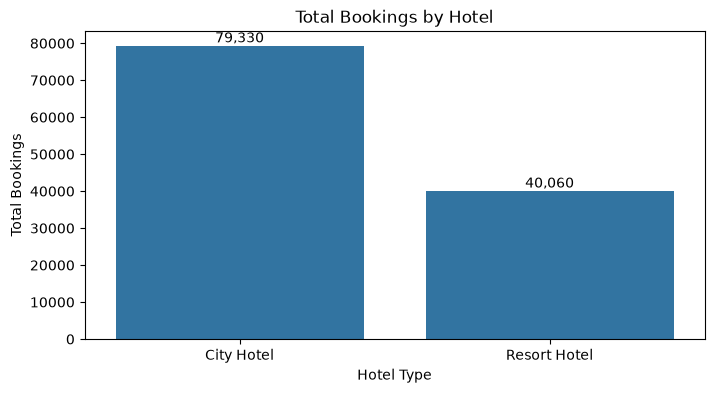

In [75]:
# Total booking bar chart
hotel_plot = hotel_summary.drop('Overall').reset_index()

plt.figure(figsize=(8,4))

ax = sns.barplot(data=hotel_plot,x='hotel',y='Total Bookings')
ax.bar_label(ax.containers[0],fmt='{:,.0f}')

plt.title('Total Bookings by Hotel')
plt.xlabel('Hotel Type')
plt.ylabel('Total Bookings')
plt.show()

In [79]:
# City Hotel accounts for approximately 66.4% of total bookings, receiving nearly twice as many bookings as Resort Hotel. 
# This indicates higher booking volume for City Hotel, although booking volume alone does not reflect actual completed stays or profitability.

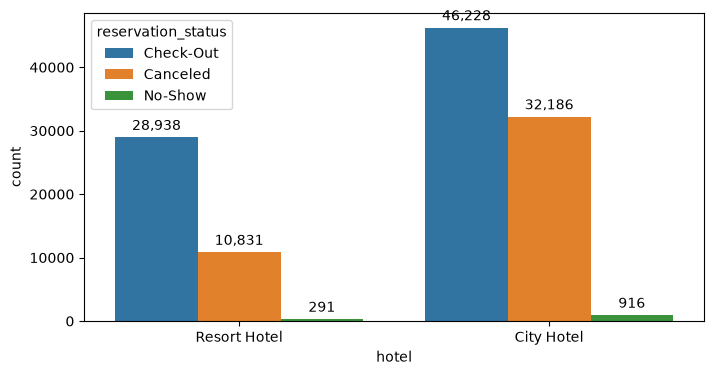

In [82]:
# Booking status by hotel chart
plt.figure(figsize=(8,4))
ax = sns.countplot(data=df,x='hotel',hue='reservation_status')

for container in ax.containers:
    ax.bar_label(container,fmt='{:,.0f}',padding=3)

plt.show()

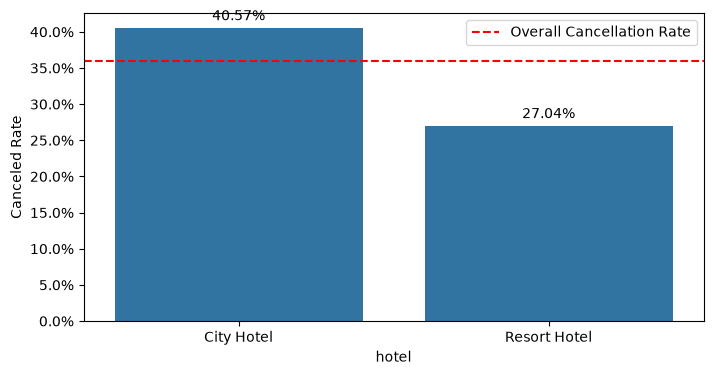

In [87]:
# Cancellation rate chart
plt.figure(figsize=(8,4))
ax = sns.barplot(data=hotel_plot,x='hotel',y='Canceled Rate')

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.bar_label(ax.containers[0],fmt='{:.2%}',padding=3)

plt.axhline(y=overall_canceled_rate,
            color='red',
            linestyle='--',
            label='Overall Cancellation Rate')
plt.legend()

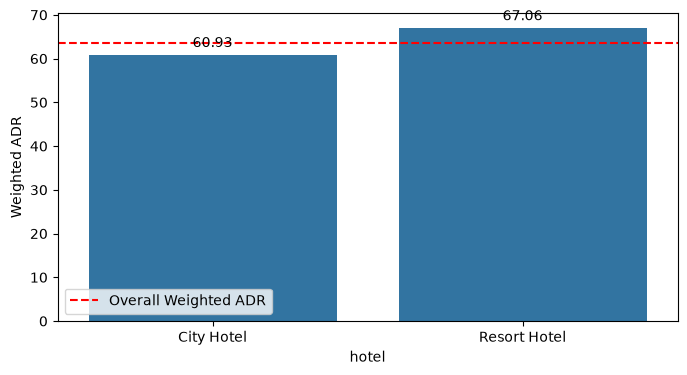

In [91]:
# Weighted ADR by hotel
plt.figure(figsize=(8,4))
ax = sns.barplot(data=hotel_plot,x='hotel',y='Weighted ADR')

ax.bar_label(ax.containers[0],fmt='{:.2f}',padding=3)

plt.axhline(y=overall_adr,
            color='red',
            linestyle='--',
            label='Overall Weighted ADR')
plt.legend()

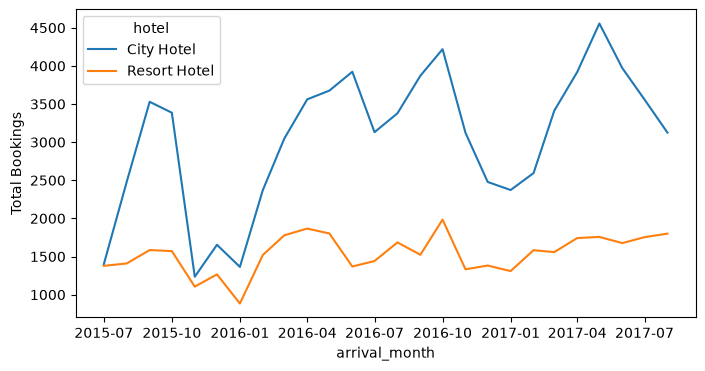

In [98]:
# Monthly trend
df['arrival_date'] = df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-' + df['arrival_date_day_of_month'].astype(str)
df['arrival_date'] = pd.to_datetime(df['arrival_date'],format='%Y-%B-%d')

df['arrival_month'] = df['arrival_date'].dt.to_period('M')
monthly_bookings = df.groupby(['arrival_month','hotel']).size().reset_index(name='Total Bookings')
monthly_bookings['arrival_month'] = monthly_bookings['arrival_month'].dt.to_timestamp()

plt.figure(figsize=(8,4))
ax = sns.lineplot(data=monthly_bookings,x='arrival_month',y='Total Bookings',hue='hotel')

In [56]:
# No-show analysis
no_show_by_hotel = df[df['reservation_status'] == 'No-Show'].groupby('hotel').size()
no_show_rate = no_show_by_hotel / total_bookings_by_hotel

no_show_summary = pd.DataFrame({
    'Total No-Show Bookings': no_show_by_hotel,
    'No-Show Rate': no_show_rate
})

total_no_show = (df['reservation_status'] == 'No-Show').sum()
overall_rate = total_no_show / total_bookings

no_show_summary.loc['Overall'] = [
    total_no_show,
    overall_rate
]

no_show_summary

,Total No-Show Bookings,No-Show Rate
hotel,,
City Hotel,916.0,0.011547
Resort Hotel,291.0,0.007264
Overall,1207.0,0.010110


In [57]:
# Completed booking analysis
completed_by_hotel = df[df['reservation_status'] == 'Check-Out'].groupby('hotel').size()
completion_rate = completed_by_hotel / total_bookings_by_hotel

completion_summary = pd.DataFrame({
    'Total Completed Bookings': completed_by_hotel,
    'Completion Rate': completion_rate
})

total_completed_bookings = (df['reservation_status'] == 'Check-Out').sum()
overall_rate = total_completed_bookings / total_bookings

completion_summary.loc['Overall'] = [
    total_completed_bookings,
    overall_rate
]

completion_summary

,Total Completed Bookings,Completion Rate
hotel,,
City Hotel,46228.0,0.582730
Resort Hotel,28938.0,0.722366
Overall,75166.0,0.629584


In [ ]:
## Hotel performance analysis

In [ ]:
# Cancel